# 🍕 Pizza à Bessa x Valentina: o que faz um Reel render mais visualizações?

**Projeto CRISP-DM | Ciência de Dados aplicada ao Marketing Digital | CEUB**
**Profa.:** Kadidja Valéria Reginaldo de Oliveira
**Grupo:** Pedro Nobre, Mell Lima, Daniel Câmara, Rodrigo Avelar, Pedro Lucas e Nicolas Balzon

---

### Em poucas palavras
Analisamos **58 Reels do Instagram** de duas pizzarias de Brasília para descobrir **que tipo de conteúdo atrai mais visualizações** e usamos isso para propor uma **campanha** para a Pizza à Bessa.

### Como ler este notebook
Cada fase do CRISP-DM tem o mesmo roteiro: **o que fazemos → o que os dados mostram → o que isso significa para a pizzaria**. O código está ali só para provar os números; o que importa é o texto.

> **Para rodar no Google Colab:** clique em **Ambiente de execução > Executar tudo**. Se o notebook pedir o arquivo, selecione o `posts_instagram.xlsx`.

In [1]:
# Preparação do ambiente (bibliotecas e cores). Não precisa mexer aqui.
import warnings, glob
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

LARANJA, ROXO, CINZA = "#F26B21", "#5B2A86", "#B8B8B8"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold"})

def mil(v):
    # 70700 -> '70,7 mil' | 254000 -> '254 mil'
    if v >= 100000:
        return f"{v/1000:.0f} mil"
    if v >= 1000:
        return f"{v/1000:.1f}".replace(".", ",") + " mil"
    return f"{v:.0f}"

# Localiza a planilha (mesmo se o Colab renomear para 'posts_instagram (1).xlsx')
arquivos = sorted(glob.glob("posts_instagram*.xlsx"))
if not arquivos:
    try:
        from google.colab import files
        print("Selecione o arquivo posts_instagram.xlsx:")
        files.upload()
        arquivos = sorted(glob.glob("posts_instagram*.xlsx"))
    except ImportError:
        pass
ARQUIVO = arquivos[0]
print("Planilha encontrada:", ARQUIVO)

Planilha encontrada: posts_instagram.xlsx


---
# Fase 1 — Compreensão do Negócio
### *Qual é o problema da pizzaria e o que queremos resolver?*

**A situação.** A Pizza à Bessa tem algo difícil de conseguir: **Reels que viralizam**, com mais de 400 mil visualizações. Mesmo assim, ela quase não aproveita isso:
- posta cerca de **2 vezes por mês**;
- tem só **4 anúncios ativos**, com mensagens parecidas, rodando há mais de 90 dias;
- tem stories desatualizados e a marca dividida em **vários perfis** de Instagram.

A concorrente **Valentina** tem bem menos alcance orgânico, mas investe mais em presença: **22 anúncios** (um deles no ar há 656 dias), 4 posts por mês, perfil verificado e aplicativo próprio.

**O problema.** A Bessa não sabe (ou não usa) **quais conteúdos mais atraem o público**, então repete as mesmas mensagens nos anúncios.

**O objetivo.** Descobrir, com dados públicos, **quais características de um Reel estão ligadas a mais visualizações** e transformar isso em uma campanha que a pizzaria possa testar.

**Como saberemos se deu certo (critérios de sucesso):**
1. Encontrar pelo menos alguns fatores de conteúdo ligados às visualizações.
2. Ter um modelo que erre **menos que um simples "chute na média"**.
3. Propor uma **campanha testável**, com indicador de resultado e cuidado com dados pessoais.

**Limite importante.** Os dados são públicos: **não temos vendas, gasto em anúncios nem número de seguidores**. Por isso **não calculamos ROI**. Usamos as visualizações como sinal de interesse do público.

---
# Fase 2 — Compreensão dos Dados
### *Que dados temos e o que eles já mostram?*

**O que fizemos.** Anotamos as visualizações de **Reels dos perfis principais** das duas pizzarias (a partir de prints do Instagram) e classificamos cada vídeo: é novo sabor? aparece o dono? mostra o salão? Como **contexto**, usamos também a Biblioteca de Anúncios do Meta, o Google Trends e o Google Maps.

In [2]:
posts = pd.read_excel(ARQUIVO, sheet_name="Posts")
com_views = posts[posts.views.notna()].copy()

print(f"Reels na planilha: {len(posts)}")
print(f"Reels usados na análise (com visualizações): {len(com_views)}  "
      f"({(com_views.perfil=='Bessa').sum()} da Bessa e {(com_views.perfil=='Valentina').sum()} da Valentina)")
print(f"Reels de foto, sem visualizações (ficam de fora): {posts.views.isna().sum()}")
print(f"Reels com classificação a ser conferida pelo grupo: {posts.obs.fillna('').str.contains('CONFERIR').sum()}")

Reels na planilha: 60
Reels usados na análise (com visualizações): 58  (35 da Bessa e 23 da Valentina)
Reels de foto, sem visualizações (ficam de fora): 2
Reels com classificação a ser conferida pelo grupo: 10


### 🔎 Descoberta 1 — O conteúdo da Bessa alcança muito mais gente
Comparamos o **Reel "típico"** de cada perfil. Usamos a **mediana**: o valor do meio, em que metade dos Reels tem mais visualizações e metade tem menos. (Ela é mais justa que a média, porque poucos vídeos gigantes inflam a média.)

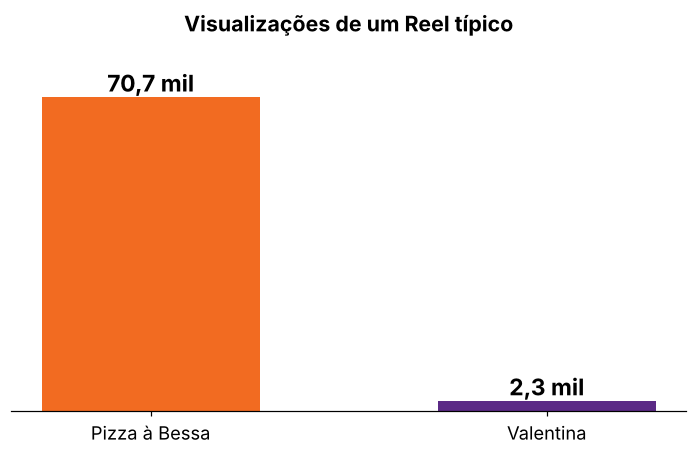

Um Reel típico da Bessa tem cerca de 30x mais visualizações que o da Valentina.


In [3]:
med = com_views.groupby("perfil").views.median()

fig, ax = plt.subplots(figsize=(6.5, 4.3))
barras = ax.bar(["Pizza à Bessa", "Valentina"], [med["Bessa"], med["Valentina"]], color=[LARANJA, ROXO], width=0.55)
for b in barras:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), mil(b.get_height()),
            ha="center", va="bottom", fontsize=15, fontweight="bold")
ax.set_ylim(0, med["Bessa"] * 1.18)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("Visualizações de um Reel típico")
plt.tight_layout(); plt.savefig("fig1_reel_tipico.png"); plt.show()
print(f"Um Reel típico da Bessa tem cerca de {med['Bessa']/med['Valentina']:.0f}x mais visualizações que o da Valentina.")

**O que isso significa:** a Bessa já tem um conteúdo que o público assiste. O problema dela **não é falta de alcance orgânico**.

### 🔎 Descoberta 2 — Mas a Valentina investe mais em presença

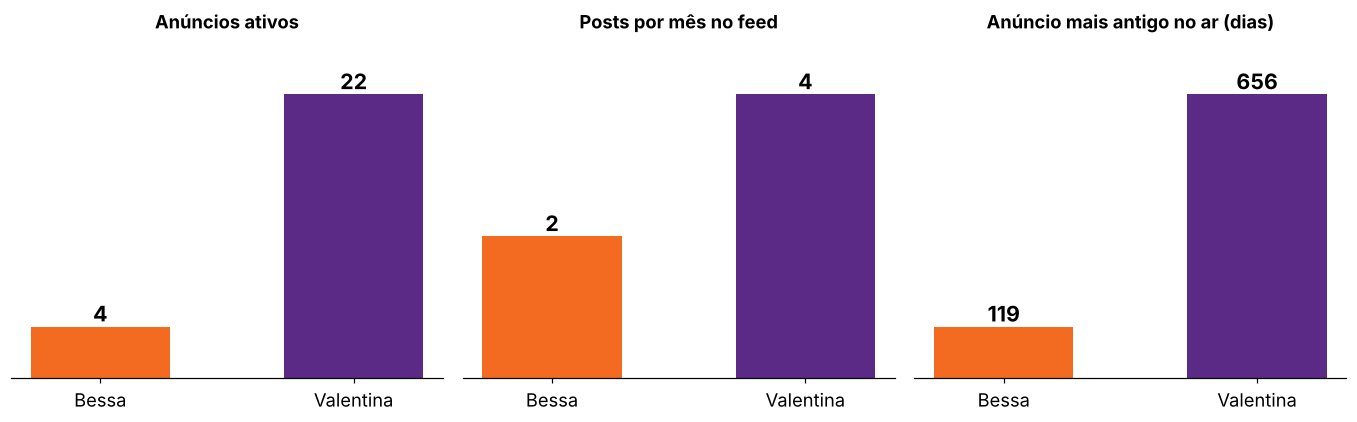

In [4]:
# Dados do estudo de caso do grupo e dos prints da Biblioteca de Anúncios do Meta
indicadores = [("Anúncios ativos", 4, 22), ("Posts por mês no feed", 2, 4), ("Anúncio mais antigo no ar (dias)", 119, 656)]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4))
for ax, (titulo, bessa_v, valentina_v) in zip(axes, indicadores):
    barras = ax.bar(["Bessa", "Valentina"], [bessa_v, valentina_v], color=[LARANJA, ROXO], width=0.55)
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.0f}",
                ha="center", va="bottom", fontsize=14, fontweight="bold")
    ax.set_ylim(0, max(bessa_v, valentina_v) * 1.2)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(titulo, fontsize=12)
plt.tight_layout(); plt.savefig("fig2_presenca.png"); plt.show()

**O que isso significa:** a Valentina mantém **um anúncio fixo que roda há 656 dias** (forte indício de que compensa, pois ninguém deixaria um anúncio quase 2 anos no ar sem retorno) e **renova campanhas o tempo todo**. A Bessa deixa 4 anúncios parados. A Biblioteca de Anúncios não mostra gasto nem resultado, então isso é **indício**, não prova.

### 🔎 Descoberta 3 — O que mais rende visualizações na Bessa?
Agrupamos os Reels da Bessa por **tema** e olhamos o Reel típico de cada grupo.

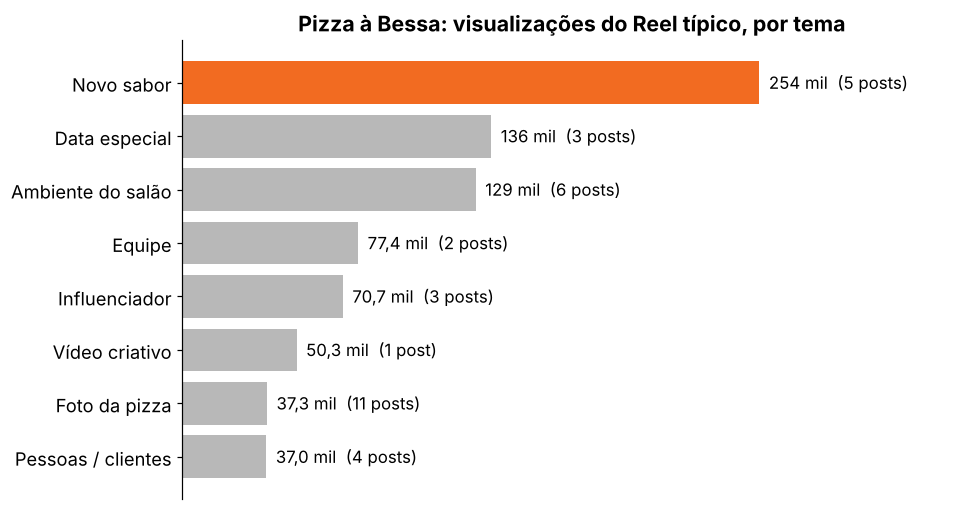

In [5]:
nomes_tema = {"novo_sabor": "Novo sabor", "sazonal": "Data especial", "ambiente": "Ambiente do salão",
              "equipe": "Equipe", "influenciador": "Influenciador", "criativo": "Vídeo criativo",
              "produto": "Foto da pizza", "pessoas": "Pessoas / clientes"}
bessa = com_views[com_views.perfil == "Bessa"]
tema = bessa.groupby("tema").views.agg(posts="count", mediana="median").sort_values("mediana")

fig, ax = plt.subplots(figsize=(9, 4.8))
cores = [LARANJA if t == "novo_sabor" else CINZA for t in tema.index]
ax.barh([nomes_tema[t] for t in tema.index], tema.mediana, color=cores)
for y, (m, n) in enumerate(zip(tema.mediana, tema.posts)):
    ax.text(m, y, f"  {mil(m)}  ({n} {'post' if n == 1 else 'posts'})", va="center", fontsize=11)
ax.set_xlim(0, tema.mediana.max() * 1.35)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Pizza à Bessa: visualizações do Reel típico, por tema")
plt.tight_layout(); plt.savefig("fig3_temas_bessa.png"); plt.show()

**O que isso significa:** os Reels de **novo sabor** vão muito melhor que os demais, seguidos de **datas especiais** e **ambiente do salão**. As **fotos da pizza** (produto), que são o conteúdo mais comum, ficam entre os piores.
⚠️ Alguns temas têm poucos posts (o número aparece entre parênteses), então para eles vale como **pista**, não como certeza.

**Os 5 Reels mais vistos da Bessa:**

In [6]:
top5 = bessa.nlargest(5, "views")[["views", "descricao"]].copy()
top5["views"] = top5["views"].map(mil)
top5.columns = ["Visualizações", "O que era o Reel"]
top5.reset_index(drop=True)

,Visualizações,O que era o Reel
0,637 mil,Homem de camisa preta falando para a câmera (i...
1,454 mil,'Novo sabor Maio - California'
2,435 mil,Paulo Bessa com chapéu do Brasil - 'Bolão Copa...
3,283 mil,'Novo sabor' - Paulo Bessa provando fatia
4,262 mil,Parede com logo e coroa Pizza à Bessa


**O que os dados nos fazem suspeitar** (hipóteses que vamos testar na modelagem):
1. Reels de **novo sabor** rendem mais visualizações.
2. Aparecer o **dono (Paulo Bessa) ou um influenciador** ajuda.
3. Mostrar o **ambiente** da pizzaria ajuda.

**Problemas encontrados nos dados:** amostra pequena (58 Reels); classificação feita à mão pelo grupo; **não temos as datas dos posts nem o número de seguidores**.

---
# Fase 3 — Preparação dos Dados
### *Arrumar a base para o computador poder aprender com ela*

**O que fizemos:**
1. Deixamos só os Reels com visualizações.
2. Transformamos cada característica em **sim (1) ou não (0)**, que é o formato que o modelo entende.
3. Aplicamos um ajuste técnico às visualizações (escala logarítmica) só para que os poucos vídeos gigantes não distorçam o cálculo. Isso acontece "por dentro": nos resultados voltamos a falar em "vezes mais visualizações".

**As perguntas que o modelo vai usar:**

| Variável | Pergunta que ela responde |
|---|---|
| `perfil_bessa` | O Reel é da Bessa (1) ou da Valentina (0)? |
| `novo_sabor` | O Reel anuncia um sabor novo? |
| `tem_rosto_marca` | Aparece o Paulo Bessa ou um influenciador? |
| `ambiente` | O Reel mostra o salão, a fachada ou a estrutura? |

In [7]:
df = com_views.copy()
df["log_views"] = np.log10(df.views)                                              # ajuste técnico do alvo
df["perfil_bessa"] = (df.perfil == "Bessa").astype(int)
df["tem_rosto_marca"] = df.pessoa.isin(["dono", "influenciador"]).astype(int)     # Paulo Bessa ou influenciador
for p in ["dono", "influenciador", "equipe", "outro"]:
    df[f"pessoa_{p}"] = (df.pessoa == p).astype(int)

FEATS = ["perfil_bessa", "novo_sabor", "tem_rosto_marca", "ambiente"]             # modelo final (4 perguntas)
FEATS_9 = ["perfil_bessa", "pessoa_dono", "pessoa_influenciador", "pessoa_equipe", "pessoa_outro",
           "sazonal", "novo_sabor", "texto_tela", "ambiente"]                     # versão com 9 perguntas, testada antes

assert df[FEATS_9 + ["log_views"]].isna().sum().sum() == 0
df.to_csv("posts_tratados.csv", index=False, encoding="utf-8-sig")
print(f"Base pronta para o modelo: {len(df)} Reels ({int(df.perfil_bessa.sum())} Bessa e {int((1-df.perfil_bessa).sum())} Valentina)")
df[["id", "perfil", "views", "perfil_bessa", "novo_sabor", "tem_rosto_marca", "ambiente"]].head(6)

Base pronta para o modelo: 58 Reels (35 Bessa e 23 Valentina)


,id,perfil,views,perfil_bessa,novo_sabor,tem_rosto_marca,ambiente
0,B01,Bessa,4055.0,1,0,0,1
1,B02,Bessa,10500.0,1,0,0,0
2,B03,Bessa,435000.0,1,0,1,0
3,B04,Bessa,454000.0,1,1,0,0
4,B05,Bessa,283000.0,1,1,1,0
5,B06,Bessa,637000.0,1,0,1,0


---
# Fase 4 — Modelagem
### *Ensinar o computador a prever as visualizações e descobrir o que mais pesa*

**O que fizemos.** Usamos **regressão**, uma técnica que estima um número (aqui, as visualizações) a partir de características do Reel. Comparamos 3 métodos:
- **Chutar a média:** o "modelo burro", que serve de régua. Se nosso modelo não for melhor que isso, ele não serve.
- **Regressão linear:** o método mais simples e fácil de explicar.
- **Random Forest:** um método mais sofisticado, para ver se complicar ajuda.

**Como testamos de forma justa.** Com poucos dados, o modelo "treina" em parte dos Reels e é testado nos que **nunca viu**, repetido 100 vezes com sorteios diferentes.

**Como medimos:** o **erro típico**: "em média, o modelo erra por um fator de quantas vezes?". Um erro de 3x significa que, se ele prevê 100 mil visualizações, o real fica entre cerca de 33 mil e 300 mil.

In [8]:
cv = RepeatedKFold(n_splits=5, n_repeats=20, random_state=42)

def testar(nome, modelo, dados, feats):
    r = cross_validate(modelo, dados[feats], dados.log_views, cv=cv, scoring=("r2", "neg_mean_absolute_error"))
    erro = 10 ** (-r["test_neg_mean_absolute_error"].mean())
    return {"Método": nome, "Erro típico (vezes)": round(erro, 1), "R² (maior é melhor)": round(r["test_r2"].mean(), 2)}

rf = RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=3, random_state=0)
so_bessa = df[df.perfil_bessa == 1]
FEATS_B = ["novo_sabor", "tem_rosto_marca", "ambiente"]

tabela = pd.DataFrame([
    testar("Chutar a média (régua)",                 DummyRegressor(), df, FEATS),
    testar("Regressão linear (modelo final)",        LinearRegression(), df, FEATS),
    testar("Random Forest",                          rf, df, FEATS),
    testar("Regressão linear com 9 perguntas",       LinearRegression(), df, FEATS_9),
    testar("Só Bessa: chutar a média",               DummyRegressor(), so_bessa, FEATS_B),
    testar("Só Bessa: regressão linear",             LinearRegression(), so_bessa, FEATS_B),
])
tabela

,Método,Erro típico (vezes),R² (maior é melhor)
0,Chutar a média (régua),5.5,-0.20
1,Regressão linear (modelo final),2.8,0.44
2,Random Forest,3.1,0.35
3,Regressão linear com 9 perguntas,3.2,0.27
4,Só Bessa: chutar a média,3.3,-0.33
5,Só Bessa: regressão linear,3.0,-0.17


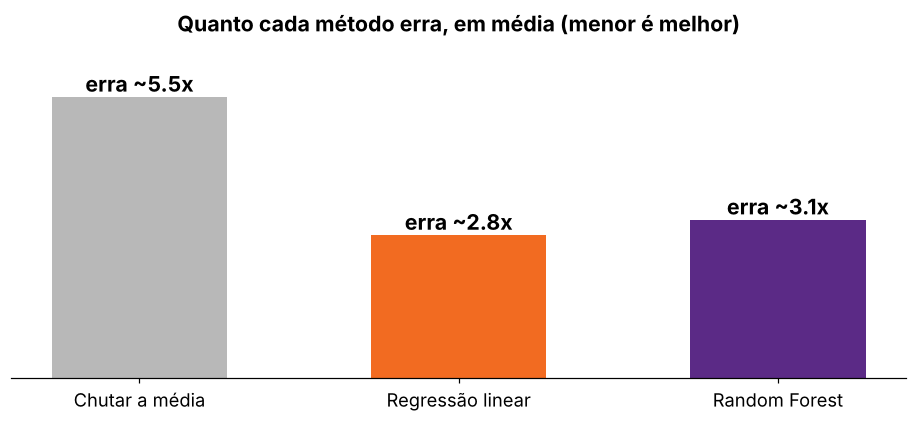

In [9]:
principais = tabela.iloc[:3]
fig, ax = plt.subplots(figsize=(8.5, 4))
cores = [CINZA, LARANJA, ROXO]
barras = ax.bar(["Chutar a média", "Regressão linear", "Random Forest"], principais["Erro típico (vezes)"], color=cores, width=0.55)
for b in barras:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"erra ~{b.get_height():.1f}x",
            ha="center", va="bottom", fontsize=14, fontweight="bold")
ax.set_ylim(0, principais["Erro típico (vezes)"].max() * 1.2)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title("Quanto cada método erra, em média (menor é melhor)")
plt.tight_layout(); plt.savefig("fig4_erro_modelos.png"); plt.show()

**O que isso significa:**
- O modelo de **regressão linear** erra bem menos que o chute na média (**~2,8x contra ~5,5x**). Ou seja, as características que usamos **realmente explicam parte** das visualizações. Ele acerta a **ordem de grandeza**, não o número exato.
- O método sofisticado (Random Forest) **não ganhou**, então ficamos com o mais simples. Testamos também 9 perguntas em vez de 4 e o resultado piorou (poucos Reels para tantas perguntas).
- Olhando **só a Bessa** (35 Reels), os dados **não bastam** para o modelo aprender: nenhum resultado ficou bom. Isso é uma limitação, não um erro.

*Transparência:* escolhemos as 4 perguntas depois de ver que 9 funcionavam pior. Leia o resultado como um **bom indício**, não como garantia.

### Quanto cada característica pesa?
Aqui está a resposta que mais importa para o marketing. Para cada característica, o modelo estima **"quantas vezes mais visualizações"** um Reel tende a ter. Depois, repetimos o cálculo 3.000 vezes com amostras sorteadas dos próprios Reels para ver se o resultado é estável: se continua forte, marcamos como **confirmado**; se oscila muito, como **indício**.

In [10]:
X, y = df[FEATS], df.log_views
final = LinearRegression().fit(X, y)

rng = np.random.default_rng(7)
boot = np.array([LinearRegression().fit(X.iloc[i], y.iloc[i]).coef_
                 for i in (rng.integers(0, len(df), len(df)) for _ in range(3000))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

rotulos = {"perfil_bessa": "Ser o perfil da Bessa (e não da Valentina)", "novo_sabor": "Reel de novo sabor",
           "tem_rosto_marca": "Paulo Bessa ou influenciador no vídeo", "ambiente": "Mostrar o ambiente do salão"}
efeitos = pd.DataFrame({
    "Característica": [rotulos[f] for f in FEATS],
    "Efeito (vezes mais views)": (10 ** final.coef_).round(1),
    "Variação possível": [f"{a:.1f}x a {b:.1f}x" for a, b in zip(10 ** lo, 10 ** hi)],
    "Conclusão": np.where((lo > 0) | (hi < 0), "Confirmado", "Indício"),
})
efeitos

,Característica,Efeito (vezes mais views),Variação possível,Conclusão
0,Ser o perfil da Bessa (e não da Valentina),9.9,5.1x a 18.6x,Confirmado
1,Reel de novo sabor,6.9,3.2x a 13.5x,Confirmado
2,Paulo Bessa ou influenciador no vídeo,2.2,0.9x a 4.9x,Indício
3,Mostrar o ambiente do salão,1.9,0.6x a 5.6x,Indício


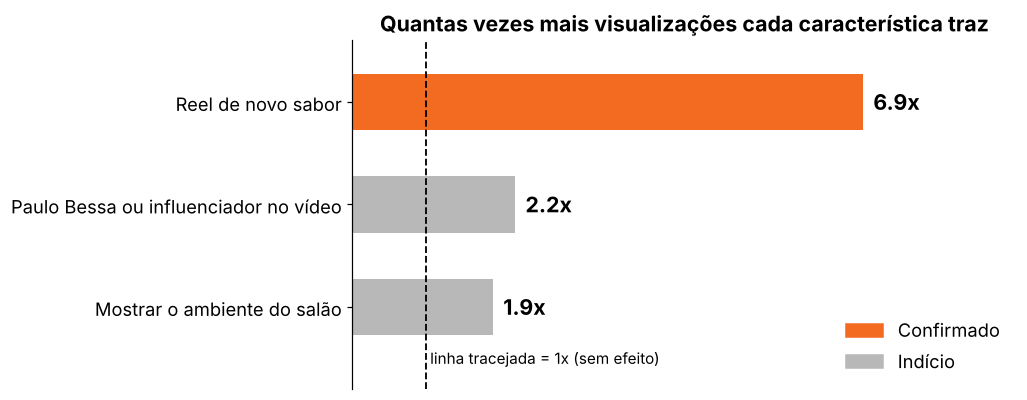

Conferindo nos Reels da Bessa: novo sabor = 254 mil no Reel típico | demais = 57,5 mil  (4.4x)


In [11]:
# Gráfico: só as características de conteúdo (a diferença entre os perfis fica no texto)
conteudo = efeitos[efeitos.Característica != rotulos["perfil_bessa"]].sort_values("Efeito (vezes mais views)")

fig, ax = plt.subplots(figsize=(9.5, 3.8))
cores = [LARANJA if c == "Confirmado" else CINZA for c in conteudo["Conclusão"]]
barras = ax.barh(conteudo["Característica"], conteudo["Efeito (vezes mais views)"], color=cores, height=0.55)
for b in barras:
    ax.text(b.get_width(), b.get_y() + b.get_height()/2, f"  {b.get_width():.1f}x", va="center", fontsize=14, fontweight="bold")
ax.axvline(1, color="black", lw=1.2, ls="--")
ax.text(1.05, -0.5, "linha tracejada = 1x (sem efeito)", ha="left", va="center", fontsize=10)
ax.set_xlim(0, conteudo["Efeito (vezes mais views)"].max() * 1.3); ax.set_ylim(-0.8, len(conteudo) - 0.4)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.legend(handles=[Patch(color=LARANJA, label="Confirmado"), Patch(color=CINZA, label="Indício")], loc="lower right", frameon=False)
ax.set_title("Quantas vezes mais visualizações cada característica traz")
plt.tight_layout(); plt.savefig("fig5_efeitos.png"); plt.show()

# Conferência direta nos números brutos (só Bessa)
nv, outros = so_bessa[so_bessa.novo_sabor == 1].views.median(), so_bessa[so_bessa.novo_sabor == 0].views.median()
print(f"Conferindo nos Reels da Bessa: novo sabor = {mil(nv)} no Reel típico | demais = {mil(outros)}  ({nv/outros:.1f}x)")

---
# Fase 5 — Avaliação
### *O resultado resolve o problema da pizzaria?*

Aqui voltamos aos **critérios de sucesso da Fase 1**.

| Critério | Resultado |
|---|---|
| **1. Fatores ligados às visualizações** | ✅ **Novo sabor é o fator confirmado**: Reels de novo sabor tendem a ter cerca de **7x mais** visualizações. 🟡 **Indícios:** aparecer Paulo Bessa/influenciador (~2x) e mostrar o ambiente (~2x). Não dá para garantir, mas apontam na mesma direção. |
| **2. Modelo melhor que o chute** | ✅ Erra ~2,8x contra ~5,5x do chute na média. |
| **3. Campanha testável** | ✅ Na Fase 6. |

**Um cuidado importante.** O modelo também mostra que ser o perfil da Bessa vale ~10x mais visualizações. Isso **mistura qualidade do conteúdo com tamanho da audiência** (não temos o número de seguidores), então **não podemos dizer que a Bessa "faz conteúdo 10x melhor"**.

**O que os dados NÃO provam:**
- **Datas especiais:** o estudo de caso sugeria que rendem mais, mas a amostra não confirma (Copa e Natal foram bem; Dia dos Namorados, com criador externo, foi mal).
- **Influenciadores:** o resultado é inconsistente (um Reel de 637 mil, mas outros criadores ficaram em 8 mil e 31 mil). Por isso, tratamos como **teste**.
- **ROI e vendas:** sem gasto e sem vendas, não dá para calcular. O anúncio de 656 dias da Valentina é só um indício de retorno.

**Decisão do ciclo.** Os critérios foram atingidos, então **não é preciso voltar à Fase 1**. No próximo ciclo, o ideal é ter **mais Reels (100 ou mais por perfil), com datas e número de seguidores**.

---
# Fase 6 — Implantação
### *Como a pizzaria usa isso na prática?*

Como usamos dados públicos, a implantação é um **plano de ação** para a Bessa testar.

## 🎯 Campanha proposta: "Sabor novo do mês"
| Elemento | Proposta |
|---|---|
| **Gatilho** | Lançamento de um sabor novo, uma vez por mês |
| **Público** | Pessoas de Brasília que já interagiram com o Instagram da Bessa nos últimos 30 dias (público de engajamento da própria plataforma) |
| **Canal** | Instagram e Facebook (Reel patrocinado), com botão de WhatsApp ou ligação, como nos anúncios atuais |
| **Ação** | Reel com **Paulo Bessa provando o sabor novo**, impulsionado por 7 dias no lugar de um dos anúncios parados |
| **Indicador de resultado** | **Custo por contato** (cliques em WhatsApp/ligação) e visualizações do Reel, comparados com os anúncios atuais |
| **Cuidado com os dados (LGPD)** | Usar só públicos de engajamento da plataforma, sem listas de clientes sem consentimento; limitar a frequência (por exemplo, até 3 vezes por semana por pessoa); responder no WhatsApp só a quem iniciou a conversa; não coletar dados pessoais |

## 🧪 Como testar direito (cuidados do teste A/B)
Comparar **"com Paulo" x "sem Paulo"**: mesmo sabor, mesma verba, mesmo período, público dividido ao acaso, e **só uma coisa muda**. Rodar por pelo menos 7 dias e só decidir se a diferença for maior que a variação normal entre dois anúncios iguais.

## 💰 Métricas de negócio (a pizzaria preenche com os dados dela)
| Métrica | Como se calcula | O que falta |
|---|---|---|
| **CAC** (custo de conquistar um cliente) | Gasto com anúncios ÷ novos clientes | Gasto (Gerenciador de Anúncios) e contagem de clientes novos |
| **LTV** (valor do cliente) | Margem por mês × meses de relacionamento | Margem e frequência de retorno |
| **ROI** (retorno) | (Margem extra − investimento) ÷ investimento | Vendas ligadas à campanha |

Não calculamos esses valores porque **não temos os dados**, e **não vamos inventar números**.

## 📅 Calendário de conteúdo (nov/2026 a abr/2027, datas a confirmar)
| Mês | Gancho | Conteúdo sugerido |
|---|---|---|
| Nov | Black Friday (27/11) | Sabor novo + combo de rodízio |
| Dez | Natal e confraternizações | "Clima de Natal" + salão para grupos |
| Jan | Férias escolares | Área kids + sabor novo |
| Fev | Carnaval (09/02) | Pizza temática do mês |
| Mar | Dia do Consumidor (15/03) e Páscoa (28/03) | Pizzas de chocolate + promoção |
| Abr | Aniversário de Brasília (21/04) | Mensagem do Paulo Bessa à cidade |

**Frequência sugerida:** subir de ~2 para 4 posts por mês e manter os stories ativos.
**Acompanhar a cada 2 meses:** visualizações do Reel típico, custo por contato, busca da marca no Google Trends e nota no Google Maps.

---
# ✅ Resumo para a apresentação
- **Observação 1:** a Bessa tem um Reel típico com ~30x mais visualizações que o da Valentina, mas a Valentina anuncia mais e renova campanhas (22 anúncios, um deles com 656 dias). A Bessa mantém 4 anúncios parados.
- **Observação 2:** Reels de **novo sabor** têm ~254 mil visualizações no Reel típico, contra ~58 mil dos demais Reels da Bessa, e o modelo confirma esse efeito.
- **Campanha:** "Sabor novo do mês" com Paulo Bessa, medida pelo custo por contato, com teste A/B.
- **Cuidado com os dados:** só públicos de engajamento da plataforma, frequência limitada e nenhum dado pessoal coletado. No nosso trabalho, usamos só dados públicos, **sem nomes de usuários**.
- **Decisão em uma frase:** lançar todo mês um Reel de sabor novo com Paulo Bessa e impulsioná-lo como anúncio; funcionou se o custo por contato cair em relação aos anúncios atuais.